# 3.  Codificación de variables

Conjunto de datos: titanic (incluido en seaborn)

Este conjunto de datos es excelente para trabajar con variables categóricas.

In [29]:
# Importar librerías necesarias
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, OneHotEncoder

In [30]:
# Cargar el conjunto de datos
data = sns.load_dataset('titanic')

In [31]:
# Visualizar las primeras filas
print("Conjunto de datos Titanic:")
data.head()

Conjunto de datos Titanic:


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [32]:
# Seleccionar columnas categóricas
categorical_cols = ['sex', 'embarked', 'class']

In [33]:
# Codificar con LabelEncoder
label_encoder = LabelEncoder()
data['sex_label'] = label_encoder.fit_transform(data['sex'])

In [34]:
# Codificar con OneHotEncoder
onehot_encoder = pd.get_dummies(data['embarked'], prefix='embarked')

In [35]:
# Combinar con el conjunto original
data = pd.concat([data, onehot_encoder], axis=1)

# Ejercicios
Contesta las siguientes preguntas. Para cada pregunta, deberás escribir código que demostrará cómo llegaste al resultado. Crea gráficas en donde veas correcto.

### 1. ¿Qué diferencias encuentras entre LabelEncoder y OneHotEncoder?

In [36]:
print("LabelEncoder convierte cada categoría en un número entero.")
print("Ejemplo en 'sex': female y male pasan a valores como 0 y 1.")
print("OneHotEncoder crea una columna por cada categoría y usa 0 o 1 para indicar su presencia.")
print("LabelEncoder es más simple, pero puede hacer parecer que hay un orden entre categorías.")
print("OneHotEncoder evita ese problema porque separa cada categoría en columnas distintas.")

LabelEncoder convierte cada categoría en un número entero.
Ejemplo en 'sex': female y male pasan a valores como 0 y 1.
OneHotEncoder crea una columna por cada categoría y usa 0 o 1 para indicar su presencia.
LabelEncoder es más simple, pero puede hacer parecer que hay un orden entre categorías.
OneHotEncoder evita ese problema porque separa cada categoría en columnas distintas.


### 2. Crea una gráfica de barras comparando las frecuencias de 'sex' antes y después de la codificación con LabelEncoder.

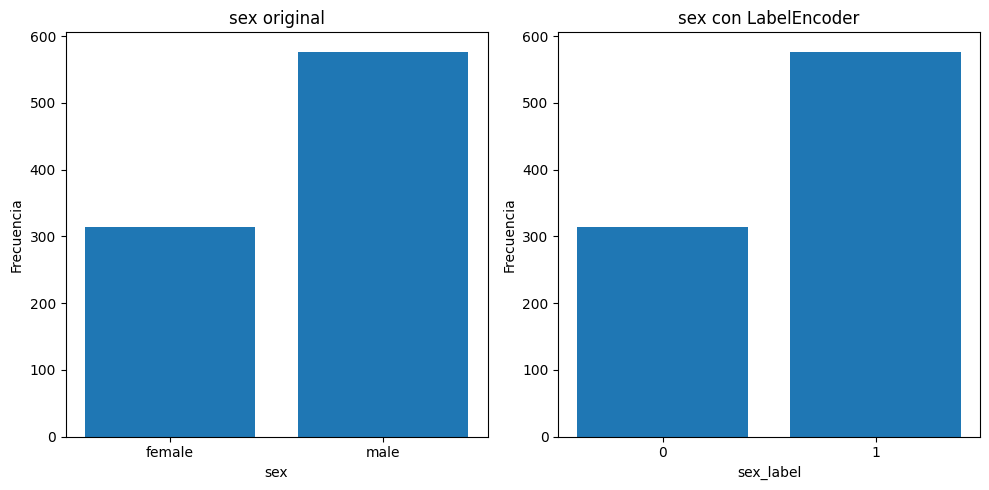

In [37]:
import matplotlib.pyplot as plt

original_counts = data['sex'].value_counts().sort_index()
encoded_counts = data['sex_label'].value_counts().sort_index()

plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.bar(original_counts.index, original_counts.values)
plt.title('sex original')
plt.xlabel('sex')
plt.ylabel('Frecuencia')

plt.subplot(1,2,2)
plt.bar(encoded_counts.index.astype(str), encoded_counts.values)
plt.title('sex con LabelEncoder')
plt.xlabel('sex_label')
plt.ylabel('Frecuencia')

plt.tight_layout()
plt.show()

### 3. Utiliza OneHotEncoder para codificar la columna 'class'. ¿Qué ventajas tiene este enfoque frente a LabelEncoder?

In [38]:
class_onehot = pd.get_dummies(data['class'], prefix='class')
print(class_onehot.head())

print("OneHotEncoder crea una columna por cada categoría y evita imponer un orden artificial entre clases, a diferencia de LabelEncoder.")

   class_First  class_Second  class_Third
0        False         False         True
1         True         False        False
2        False         False         True
3         True         False        False
4        False         False         True
OneHotEncoder crea una columna por cada categoría y evita imponer un orden artificial entre clases, a diferencia de LabelEncoder.


### 4. Si quisieras aplicar un modelo de aprendizaje automático, ¿qué tipo de codificación elegirías para las variables categóricas? Explica tu respuesta.

onehotencode porque no pone orden de numeracion falso entre las categorias